# 🌿 Notebook 1: Plant Biopotential Time-Series EDA & Feature Engineering

## 1. Project Background & Electrophysiology
Plant electrophysiology measures electrical potential differences across plant tissues generated by ion transport ($Ca^{2+}, K^{+}, Cl^{-}$ fluxes).
Using an **AD8232 analog front-end biopotential amplifier** connected to an Arduino, ADC readings (0–1023) are recorded at high temporal resolution.

> **Data Quality Rule Applied:** Any recording labeled `dead` that contains signal values other than 0 is rejected as erroneous sensor contact. Genuine dead tissue produces flatline zero electrical response.

All figures generated in this notebook will be saved automatically to `plot/01_time_series_eda_and_feature_extraction/`.


In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, signal

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

NOTEBOOK_NAME = "01_time_series_eda_and_feature_extraction"
if os.path.basename(os.getcwd()) == "notebook":
    PLOT_DIR = os.path.join("..", "plot", NOTEBOOK_NAME)
else:
    PLOT_DIR = os.path.join("plot", NOTEBOOK_NAME)
os.makedirs(PLOT_DIR, exist_ok=True)
print(f"Plots will be saved to: {os.path.abspath(PLOT_DIR)}")


Plots will be saved to: C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\plot\01_time_series_eda_and_feature_extraction


## 2. Load & Explore Time-Series Sessions Across Categories

In [2]:
DATA_ROOT = os.path.join("..", "categorize csv")
if not os.path.exists(DATA_ROOT):
    DATA_ROOT = "categorize csv"

categories = ["normal", "music/classical", "music/devotional", "music/pop", "music/general", "water", "dead"]
file_inventory = []

for cat in categories:
    cat_dir = os.path.join(DATA_ROOT, os.path.normpath(cat))
    csv_files = glob.glob(os.path.join(cat_dir, "*.csv"))
    for f in csv_files:
        try:
            df_temp = pd.read_csv(f)
            # Filter check: if dead file has any non-zero signal, reject it
            if "dead" in cat and (df_temp["ecg"] != 0).any():
                print(f"Excluding invalid non-zero dead file: {os.path.basename(f)}")
                continue
            if len(df_temp) > 50:
                file_inventory.append({
                    "filepath": f,
                    "filename": os.path.basename(f),
                    "category": cat,
                    "rows": len(df_temp)
                })
        except Exception:
            pass

inventory_df = pd.DataFrame(file_inventory)
print(f"Total verified time-series sessions: {len(inventory_df)}")
print(inventory_df.groupby("category")["rows"].agg(["count", "sum", "mean"]))


Total verified time-series sessions: 27
                  count     sum          mean
category                                     
dead                  1    6000   6000.000000
music/classical       1   59569  59569.000000
music/devotional      6  444558  74093.000000
music/general         1   40508  40508.000000
music/pop             4  228718  57179.500000
normal               11  405429  36857.181818
water                 3  110419  36806.333333


## 3. Raw Waveform Comparison Across Stimuli

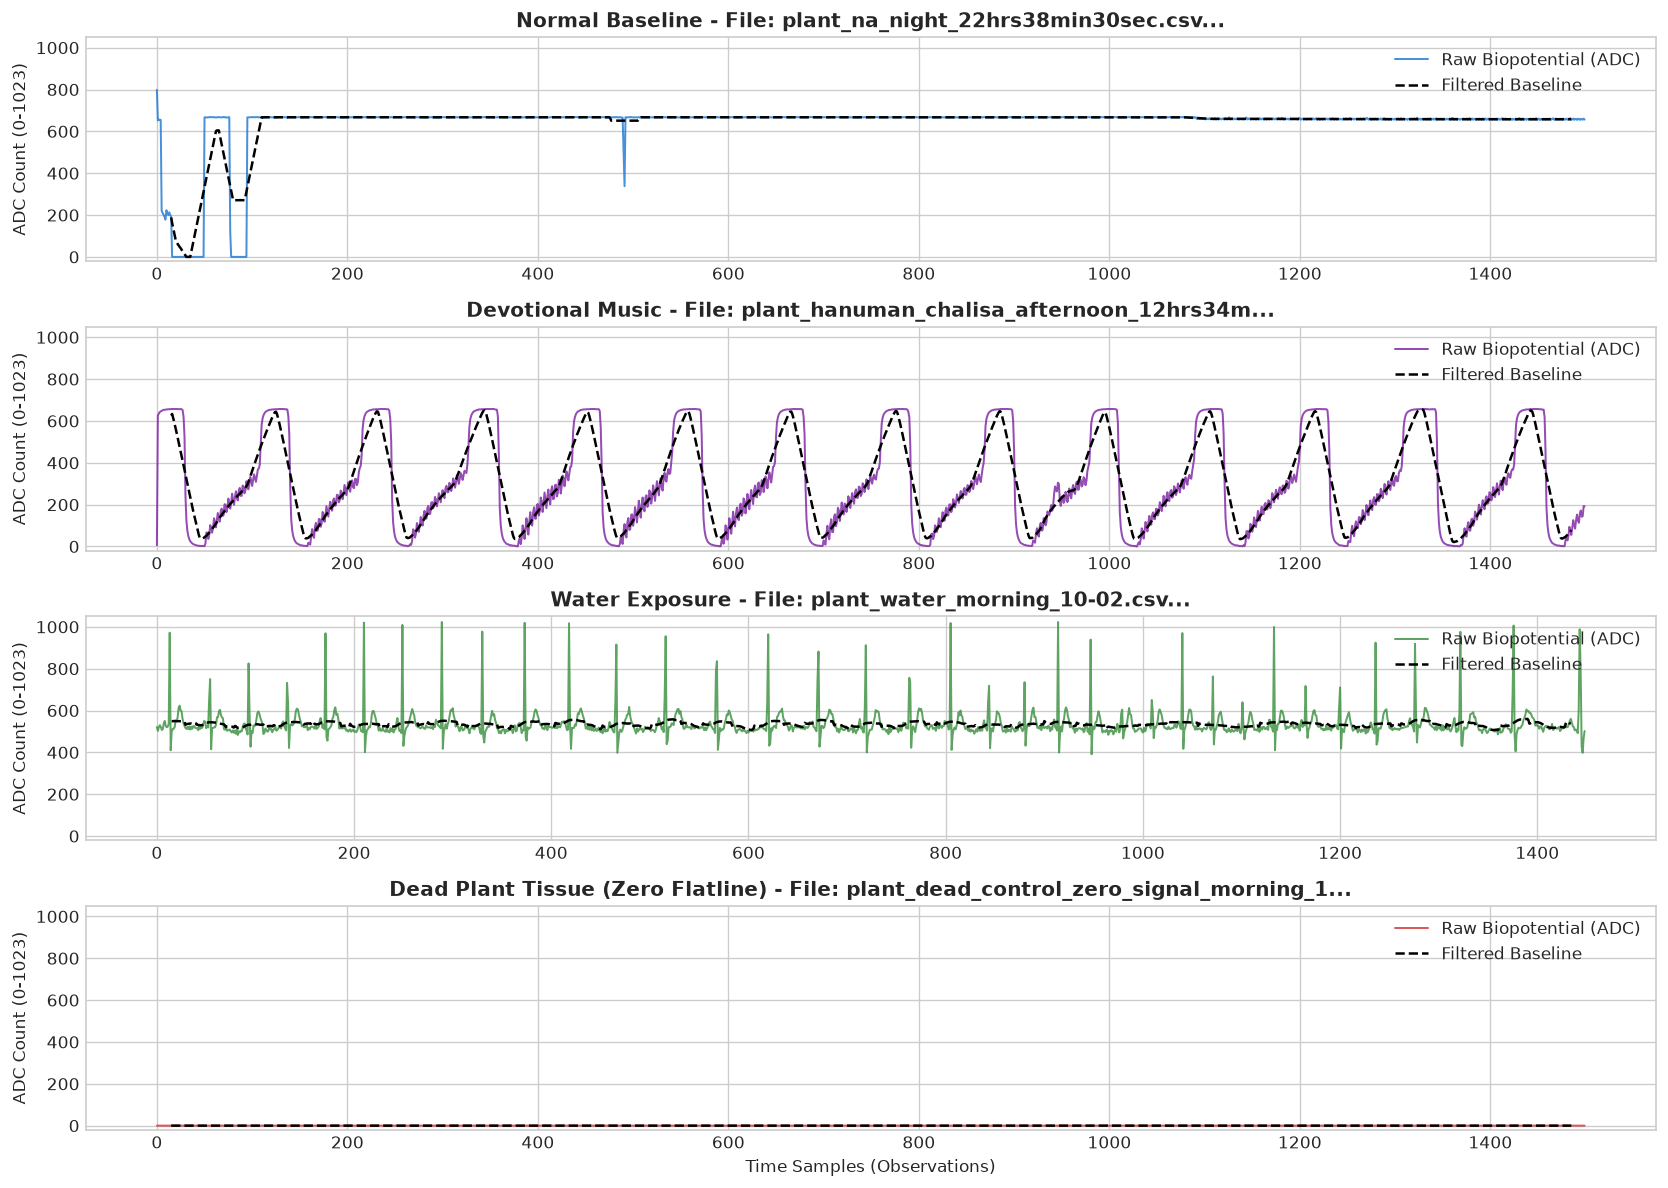

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=False)
sample_map = {
    "Normal Baseline": ("normal", "#1976D2"),
    "Devotional Music": ("music/devotional", "#7B1FA2"),
    "Water Exposure": ("water", "#388E3C"),
    "Dead Plant Tissue (Zero Flatline)": ("dead", "#D32F2F")
}

for ax, (title, (cat, color)) in zip(axes, sample_map.items()):
    matched = inventory_df[inventory_df["category"] == cat]
    if len(matched) > 0:
        sample_file = matched["filepath"].iloc[0]
        df_sample = pd.read_csv(sample_file, nrows=1500)
        signal_vals = df_sample["ecg"].values
        time_pts = np.arange(len(signal_vals))
        
        ax.plot(time_pts, signal_vals, color=color, alpha=0.8, linewidth=1.2, label="Raw Biopotential (ADC)")
        rolling_mean = pd.Series(signal_vals).rolling(window=30, center=True).mean()
        ax.plot(time_pts, rolling_mean, color="black", linestyle="--", linewidth=1.5, label="Filtered Baseline")
        
        ax.set_title(f"{title} - File: {os.path.basename(sample_file)[:40]}...", fontweight='bold')
        ax.set_ylabel("ADC Count (0-1023)")
        ax.set_ylim(-20, 1050)
        ax.legend(loc="upper right", framealpha=0.9)

axes[-1].set_xlabel("Time Samples (Observations)")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "1_raw_waveform_comparison.png"), dpi=300, bbox_inches='tight')
plt.show()


## 4. Spectral Domain: Power Spectral Density (PSD) & FFT Analysis

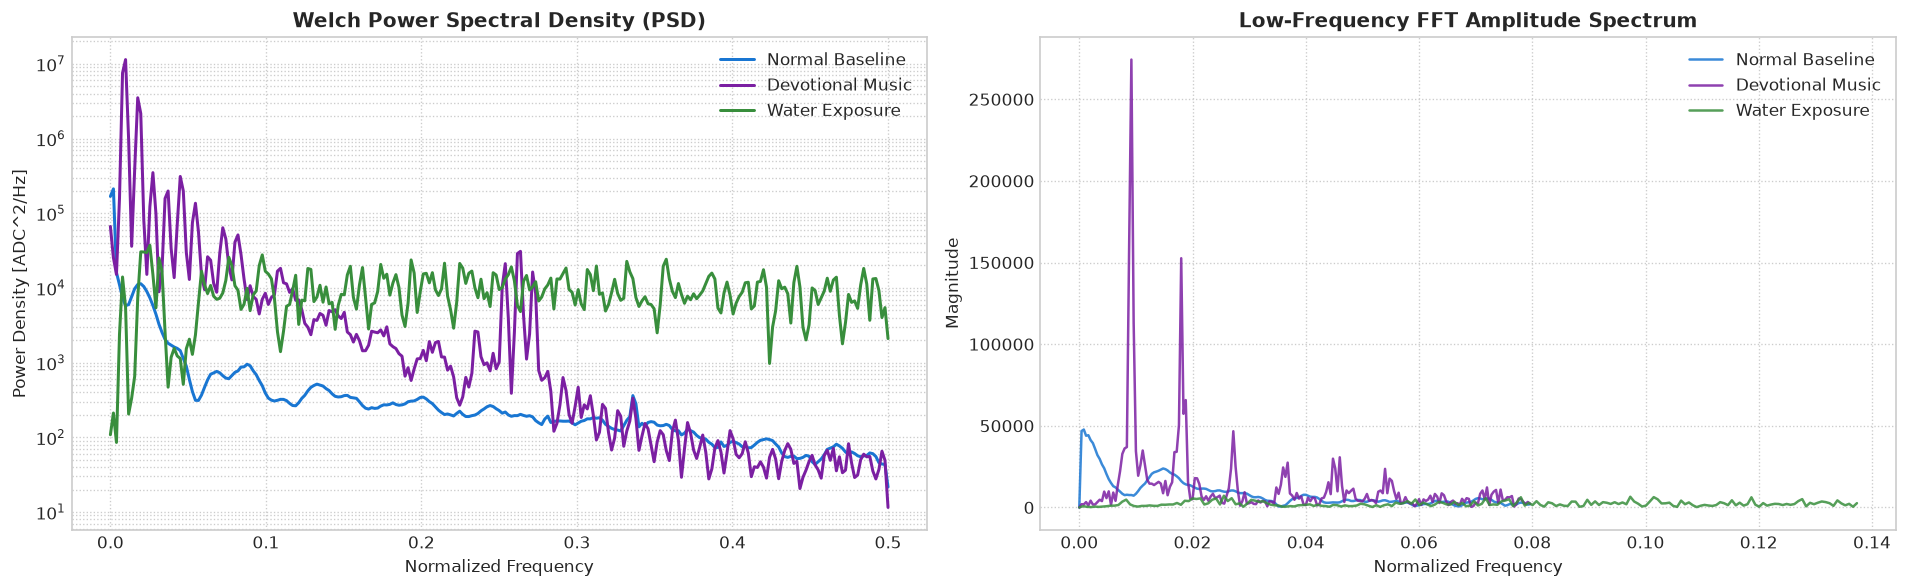

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

for title, (cat, color) in sample_map.items():
    matched = inventory_df[inventory_df["category"] == cat]
    if len(matched) > 0:
        sample_file = matched["filepath"].iloc[0]
        df_sample = pd.read_csv(sample_file, nrows=2500)
        sig = df_sample["ecg"].values - np.mean(df_sample["ecg"].values)
        if np.std(sig) > 0:
            freqs, psd = signal.welch(sig, nperseg=min(512, len(sig)))
            ax1.semilogy(freqs, psd, label=title, color=color, linewidth=1.8)
            
            fft_vals = np.abs(np.fft.rfft(sig))
            fft_freqs = np.fft.rfftfreq(len(sig))
            ax2.plot(fft_freqs[:200], fft_vals[:200], label=title, color=color, linewidth=1.5, alpha=0.85)

ax1.set_title("Welch Power Spectral Density (PSD)", fontweight='bold')
ax1.set_xlabel("Normalized Frequency")
ax1.set_ylabel("Power Density [ADC^2/Hz]")
ax1.legend()
ax1.grid(True, which='both', linestyle=':')

ax2.set_title("Low-Frequency FFT Amplitude Spectrum", fontweight='bold')
ax2.set_xlabel("Normalized Frequency")
ax2.set_ylabel("Magnitude")
ax2.legend()
ax2.grid(True, linestyle=':')

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "2_psd_fft_spectrum.png"), dpi=300, bbox_inches='tight')
plt.show()


## 5. Rolling Volatility & Dynamic Variance Analysis

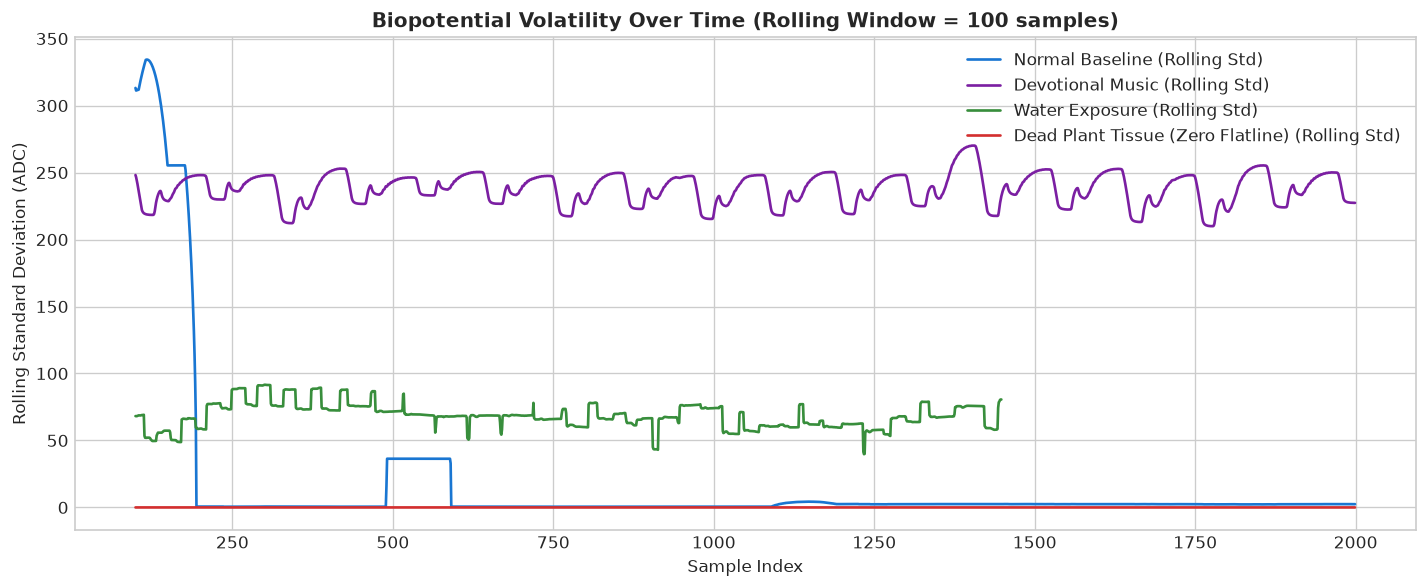

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

for title, (cat, color) in sample_map.items():
    matched = inventory_df[inventory_df["category"] == cat]
    if len(matched) > 0:
        sample_file = matched["filepath"].iloc[0]
        df_sample = pd.read_csv(sample_file, nrows=2000)
        rolling_std = pd.Series(df_sample["ecg"]).rolling(window=100).std()
        ax.plot(rolling_std.values, label=f"{title} (Rolling Std)", color=color, linewidth=1.6)

ax.set_title("Biopotential Volatility Over Time (Rolling Window = 100 samples)", fontweight='bold')
ax.set_xlabel("Sample Index")
ax.set_ylabel("Rolling Standard Deviation (ADC)")
ax.legend(loc='upper right')
ax.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "3_rolling_volatility.png"), dpi=300, bbox_inches='tight')
plt.show()


## 6. Time-Series Sliding Window Feature Engineering Pipeline

In [6]:
def extract_window_features(sig):
    N = len(sig)
    if N < 10: return None
    mean_val, std_val, var_val = float(np.mean(sig)), float(np.std(sig)), float(np.var(sig))
    min_val, max_val = float(np.min(sig)), float(np.max(sig))
    median_val = float(np.median(sig))
    rms_val = float(np.sqrt(np.mean(sig**2)))
    mad_val = float(np.mean(np.abs(np.diff(sig)))) if N > 1 else 0.0
    p25, p75 = np.percentile(sig, [25, 75])
    zcr_val = int(np.sum(np.diff(sig > mean_val) != 0)) / (N - 1) if N > 1 else 0.0
    skew_val = float(stats.skew(sig)) if std_val > 1e-5 else 0.0
    kurt_val = float(stats.kurtosis(sig)) if std_val > 1e-5 else 0.0
    peaks, _ = signal.find_peaks(sig, height=mean_val + std_val) if std_val > 0 else ([], None)
    centered = sig - mean_val
    fft_vals = np.abs(np.fft.rfft(centered))**2
    total_power = np.sum(fft_vals) + 1e-9
    num_bins = len(fft_vals)
    b1, b2 = int(num_bins * 0.25), int(num_bins * 0.50)
    low_power = float(np.sum(fft_vals[:b1]) / total_power)
    mid_power = float(np.sum(fft_vals[b1:b2]) / total_power)
    high_power = float(np.sum(fft_vals[b2:]) / total_power)
    norm_fft = fft_vals / total_power
    norm_fft = norm_fft[norm_fft > 0]
    spectral_entropy = float(-np.sum(norm_fft * np.log2(norm_fft + 1e-12))) if len(norm_fft) > 0 else 0.0
    dominant_freq = int(np.argmax(fft_vals)) if len(fft_vals) > 0 else 0
    return {
        'mean': mean_val, 'std': std_val, 'var': var_val, 'min': min_val, 'max': max_val,
        'range': max_val - min_val, 'median': median_val, 'rms': rms_val, 'mad': mad_val,
        'p25': float(p25), 'p75': float(p75), 'iqr': float(p75 - p25), 'zcr': zcr_val,
        'skew': skew_val, 'kurt': kurt_val, 'peak_count': len(peaks),
        'low_freq_power': low_power, 'mid_freq_power': mid_power, 'high_freq_power': high_power,
        'spectral_entropy': spectral_entropy, 'dominant_freq': dominant_freq
    }

print("Feature extractor defined with 21 engineered time-series features.")


Feature extractor defined with 21 engineered time-series features.


## 7. Execute Feature Extraction Across All Verified Sessions

In [7]:
WINDOW_SIZE = 200
features_records = []

for idx, row in inventory_df.iterrows():
    fpath = row["filepath"]
    category = row["category"]
    filename = row["filename"]
    
    if "dead" in category:
        main_cat = "dead"
        is_alive = 0
    elif "water" in category:
        main_cat = "water"
        is_alive = 1
    elif "music" in category:
        main_cat = "music"
        is_alive = 1
    else:
        main_cat = "normal"
        is_alive = 1
        
    df_file = pd.read_csv(fpath)
    if "ecg" not in df_file.columns or len(df_file) < WINDOW_SIZE:
        continue
    if is_alive == 0 and (df_file["ecg"] != 0).any():
        continue
        
    ecg_data = df_file["ecg"].values
    time_of_day = df_file["time_of_day"].iloc[0] if "time_of_day" in df_file.columns else "morning"
    max_windows = min(len(ecg_data) // WINDOW_SIZE, 300)
    
    for w in range(max_windows):
        window_sig = ecg_data[w*WINDOW_SIZE : (w+1)*WINDOW_SIZE]
        feats = extract_window_features(window_sig)
        if feats is not None:
            feats["session_id"] = filename
            feats["category"] = category
            feats["main_category"] = main_cat
            feats["time_of_day"] = time_of_day
            feats["is_alive"] = is_alive
            feats["window_idx"] = w
            features_records.append(feats)

features_df = pd.DataFrame(features_records)
print(f"Extracted {len(features_df)} time-series feature windows.")
print(features_df["main_category"].value_counts())

features_df.to_csv("plant_time_series_features.csv", index=False)
if os.path.exists(".."):
    features_df.to_csv(os.path.join("..", "plant_time_series_features.csv"), index=False)


Extracted 3529 time-series feature windows.
main_category
music     2195
normal     963
water      341
dead        30
Name: count, dtype: int64


## 8. Feature Correlation & Pairwise Analysis

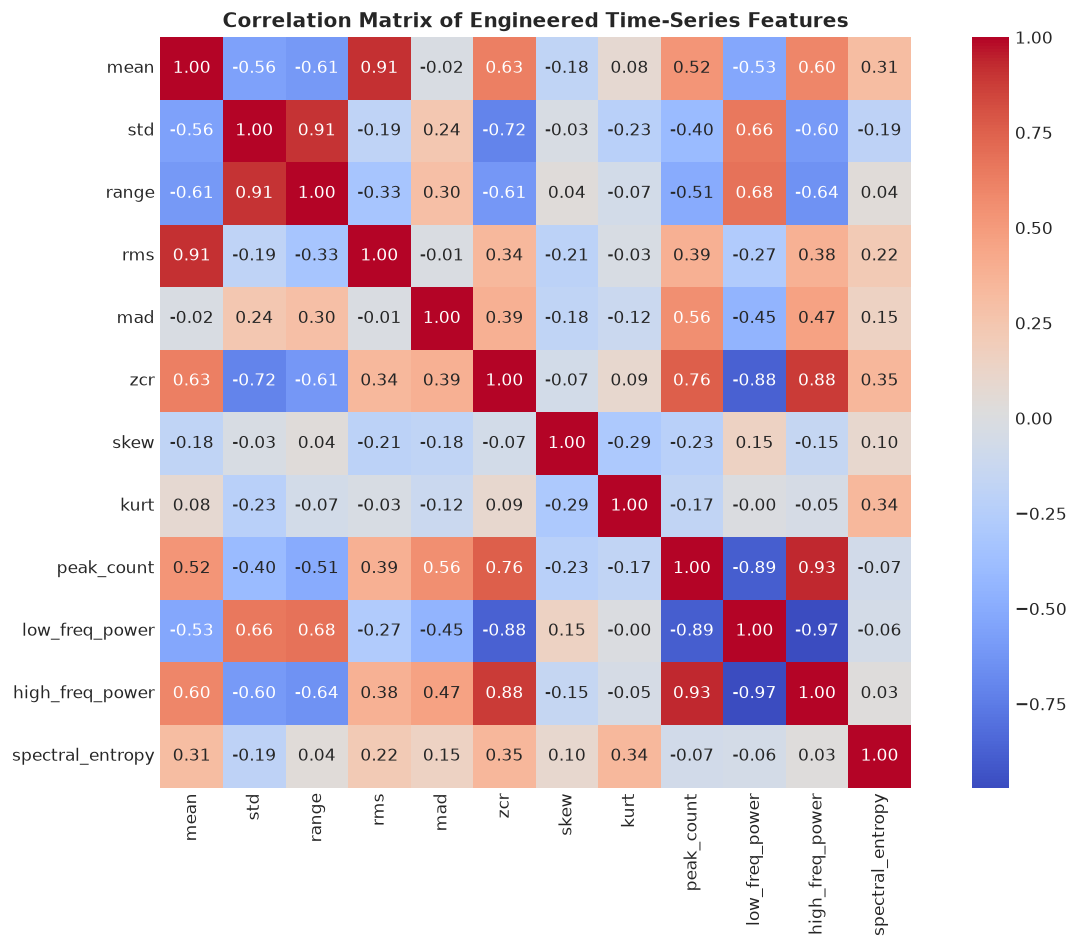

In [8]:
feature_cols = [
    "mean", "std", "range", "rms", "mad", "zcr", 
    "skew", "kurt", "peak_count", "low_freq_power", 
    "high_freq_power", "spectral_entropy"
]

plt.figure(figsize=(11, 8))
corr = features_df[feature_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Matrix of Engineered Time-Series Features", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "4_feature_correlation_matrix.png"), dpi=300, bbox_inches='tight')
plt.show()


## 9. Distribution of Key Features Across Categories

C:\Users\asim\AppData\Local\Temp\ipykernel_8464\2675454960.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=features_df, x="main_category", y=m_col, ax=ax, palette="Set2")
C:\Users\asim\AppData\Local\Temp\ipykernel_8464\2675454960.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=features_df, x="main_category", y=m_col, ax=ax, palette="Set2")
C:\Users\asim\AppData\Local\Temp\ipykernel_8464\2675454960.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=features_df, x="main_category", y=m_col, ax=ax, palette="Set2"

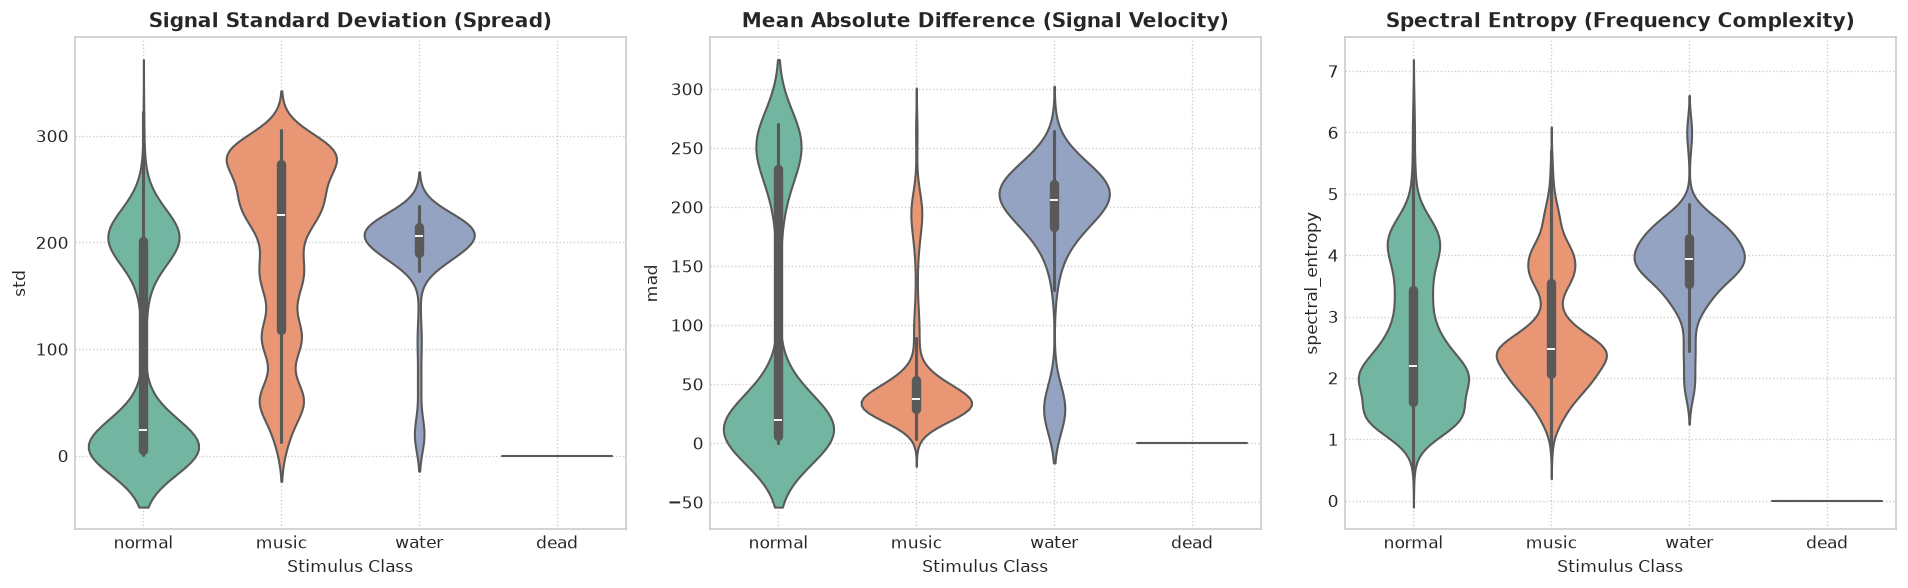

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [("std", "Signal Standard Deviation (Spread)"), 
           ("mad", "Mean Absolute Difference (Signal Velocity)"), 
           ("spectral_entropy", "Spectral Entropy (Frequency Complexity)")]

for ax, (m_col, m_title) in zip(axes, metrics):
    sns.violinplot(data=features_df, x="main_category", y=m_col, ax=ax, palette="Set2")
    ax.set_title(m_title, fontweight='bold')
    ax.set_xlabel("Stimulus Class")
    ax.grid(True, linestyle=':')

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "5_feature_distributions_violin.png"), dpi=300, bbox_inches='tight')
plt.show()
